# The geometry of $A\mathbf{x} = \mathbf{b}$

Goes with the lecture note [The geometry of $A\mathbf{x} = \mathbf{b}$ (PDF)](https://github.com/imanmossavat/ml-teaching-materials-fontys/blob/main/AP/DETH/notes/geometry-of-linear-systems.pdf).
Run the cells from top to bottom, then change the numbers.

**The idea:** a matrix is an operation that moves vectors. Solving $A\mathbf{x}=\mathbf{b}$ means finding where a vector
was *before* the operation. Sometimes that is impossible.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def rotation(theta):
    return np.array([[np.cos(theta), -np.sin(theta)],
                     [np.sin(theta),  np.cos(theta)]])

def scaling(s1, s2):
    return np.array([[s1, 0.0],
                     [0.0, s2]])

def axes(ax, title, lim=6):
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.grid(True, linestyle="--", linewidth=0.5)
    ax.axhline(0, color="black", linewidth=1); ax.axvline(0, color="black", linewidth=1)
    ax.set_title(title)

def arrow(ax, v, color, label=None, alpha=1.0):
    ax.quiver(0, 0, v[0], v[1], angles="xy", scale_units="xy", scale=1, color=color, label=label, alpha=alpha)

# a cloud of points in two colours (left and right half), centred at the origin
rng = np.random.default_rng(0)
X = rng.normal(0, 0.5, (200, 2))
colour = np.repeat([0, 1], 100)
X[:, 0] += np.where(colour == 0, -1.5, 1.5)
X[:, 1] += np.where(colour == 0, -0.8, 0.8)

def show(matrices, titles, lim=6):
    "Grey: the points before. Colour: after the matrix."
    fig, axs = plt.subplots(1, len(matrices), figsize=(4 * len(matrices), 4), squeeze=False)
    for ax, A, title in zip(axs[0], matrices, titles):
        Y = X @ A.T                      # applies A to every row of X
        ax.scatter(*X.T, c="lightgray", s=12)
        ax.scatter(*Y.T, c=colour, s=12)
        axes(ax, title, lim)
    plt.show()

## 1. Where do the basis vectors land?

The **columns of $A$** are where $\mathbf{e}_1=(1,0)$ and $\mathbf{e}_2=(0,1)$ land. Every other vector follows:
$A\mathbf{v} = v_1\,A\mathbf{e}_1 + v_2\,A\mathbf{e}_2$.

Why? Write $\mathbf{v} = v_1\mathbf{e}_1 + v_2\mathbf{e}_2$. A matrix is **linear**: it keeps sums and multiples. So

$$A\mathbf{v} = \begin{pmatrix} a & b\\ c & d\end{pmatrix}\begin{pmatrix} v_1\\ v_2\end{pmatrix}
= v_1\begin{pmatrix} a\\ c\end{pmatrix} + v_2\begin{pmatrix} b\\ d\end{pmatrix}.$$

So solving $A\mathbf{x}=\mathbf{b}$ also asks: *how much of each column do we need to build $\mathbf{b}$?*

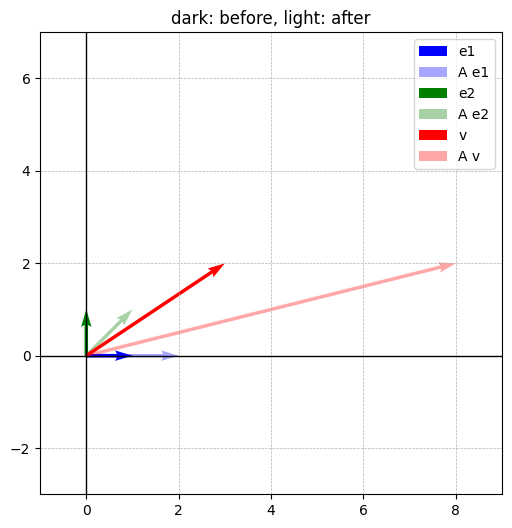

A v                     = [8 2]
v1 * A e1 + v2 * A e2   = [8 2]


In [2]:
A = np.array([[2, 1],
              [0, 1]])
v = np.array([3, 2])
e1, e2 = np.array([1, 0]), np.array([0, 1])

fig, ax = plt.subplots(figsize=(6, 6))
for u, c, name in [(e1, "blue", "e1"), (e2, "green", "e2"), (v, "red", "v")]:
    arrow(ax, u, c, name)
    arrow(ax, A @ u, c, "A " + name, alpha=0.35)
axes(ax, "dark: before, light: after"); ax.set_xlim(-1, 9); ax.set_ylim(-3, 7); ax.legend(); plt.show()

print("A v                     =", A @ v)
print("v1 * A e1 + v2 * A e2   =", v[0] * (A @ e1) + v[1] * (A @ e2))

**Your turn:** change `A` and `v`. Predict where `e1` and `e2` land *before* you run the cell.

## 2. Scaling: stretch and compress

$$S = \begin{pmatrix} s_1 & 0\\ 0 & s_2\end{pmatrix}, \qquad S\mathbf{x} = \begin{pmatrix} s_1 x_1\\ s_2 x_2\end{pmatrix}.$$

Each coordinate is multiplied separately. $|s| > 1$ stretches, $|s| < 1$ compresses, and a negative $s$ mirrors.
If $s_1, s_2 \neq 0$, dividing again undoes it: $S^{-1} = \mathrm{scaling}(1/s_1,\ 1/s_2)$.

The code stores one point per **row** of `X`. Therefore `X @ A.T` applies $A$ to every point.

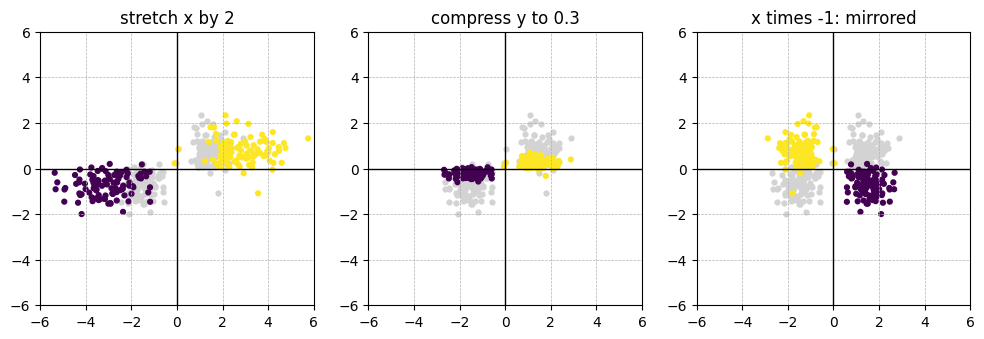

In [3]:
show([scaling(2, 1), scaling(1, 0.3), scaling(-1, 1)],
     ["stretch x by 2", "compress y to 0.3", "x times -1: mirrored"])

## 3. Rotation, and rotating back

$$R(\theta) = \begin{pmatrix} \cos\theta & -\sin\theta\\ \sin\theta & \cos\theta\end{pmatrix}$$

The columns follow from the unit circle: $\mathbf{e}_1$ lands on $(\cos\theta, \sin\theta)$ and $\mathbf{e}_2$ on
$(-\sin\theta, \cos\theta)$. Rotation keeps lengths and angles.

Going back means turning by $-\theta$. Since $\cos(-\theta) = \cos\theta$ and $\sin(-\theta) = -\sin\theta$,
$R(-\theta) = R(\theta)^\top$, and $\cos^2\theta + \sin^2\theta = 1$ gives $R(-\theta)\,R(\theta) = I$.
So $R^{-1} = R^\top$.

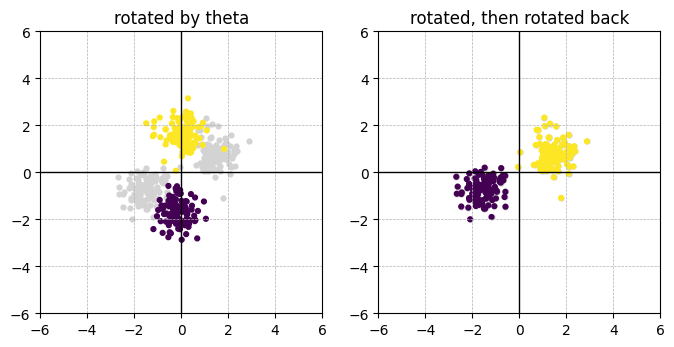

Largest difference from the original points: 4.440892098500626e-16
Is the inverse of R equal to rotation(-theta)? True


In [4]:
theta = np.pi / 3
R = rotation(theta)
X_rot = X @ R.T
X_back = X_rot @ rotation(-theta).T

show([R, rotation(-theta) @ R], ["rotated by theta", "rotated, then rotated back"])
print("Largest difference from the original points:", np.abs(X_back - X).max())
print("Is the inverse of R equal to rotation(-theta)?", np.allclose(np.linalg.inv(R), rotation(-theta)))

## 4. Two operations: does the order matter?

$RS\mathbf{x}$ means: first scale, then rotate. For $R = R(\theta)$:

$$RS = \begin{pmatrix} s_1\cos\theta & -s_2\sin\theta\\ s_1\sin\theta & s_2\cos\theta\end{pmatrix},
\qquad SR = \begin{pmatrix} s_1\cos\theta & -s_1\sin\theta\\ s_2\sin\theta & s_2\cos\theta\end{pmatrix}.$$

Compare them: when are they equal? To undo $RS$, undo the last step first: $(RS)^{-1} = S^{-1}R^{-1}$.

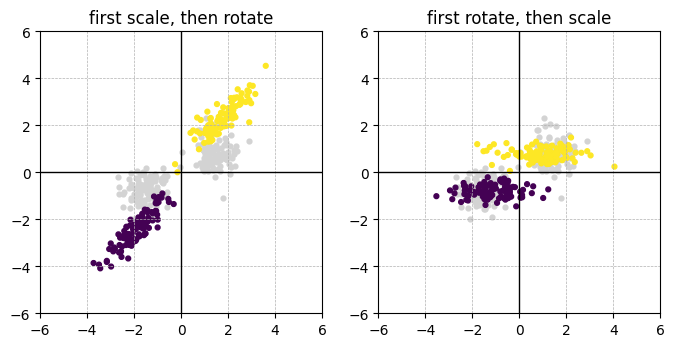

In [5]:
R, S = rotation(np.pi / 4), scaling(2, 0.5)
show([R @ S, S @ R], ["first scale, then rotate", "first rotate, then scale"])

**Your turn:** apply two rotations after each other. Does the order matter now? Why?

## 5. The determinant: how much do areas change?

The unit square has area 1. After $A$ it is a parallelogram with sides $(a, c)$ and $(b, d)$. Its area is $|\det A|$, with

$$\det\begin{pmatrix} a & b\\ c & d\end{pmatrix} = ad - bc.$$

Every area is multiplied by this factor. A negative determinant means the plane is also mirrored. For two steps after
each other the factors multiply: $\det(AB) = \det A \cdot \det B$.

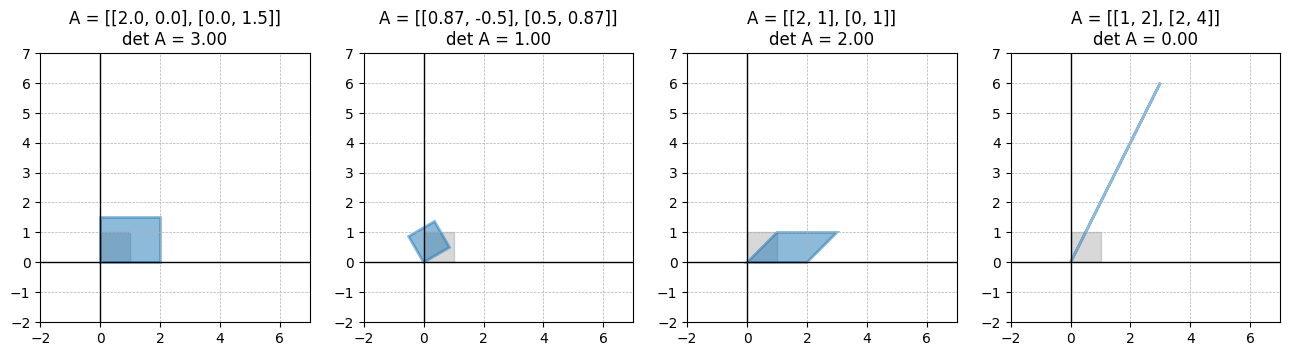

In [6]:
square = np.array([[0, 0], [1, 0], [1, 1], [0, 1]])

matrices = [scaling(2, 1.5), rotation(np.pi / 6), np.array([[2, 1], [0, 1]]), np.array([[1, 2], [2, 4]])]
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for ax, A in zip(axs, matrices):
    ax.fill(*square.T, color="gray", alpha=0.3)
    after = square @ A.T
    ax.fill(*after.T, facecolor="tab:blue", edgecolor="tab:blue", alpha=0.5, linewidth=2)
    axes(ax, f"A = {np.round(A, 2).tolist()}\ndet A = {np.linalg.det(A):.2f}"); ax.set_xlim(-2, 7); ax.set_ylim(-2, 7)
plt.show()

## 6. Crushing space

Make $s_2$ smaller and smaller. Then try to go back with the inverse. For $A = R\,S$ with $s_1 = 2$:

$$\det A = \det R \cdot \det S = 1 \cdot 2 s_2, \qquad A^{-1} = S^{-1}R^\top.$$

$S^{-1}$ contains $1/s_2$. It grows without limit as $s_2 \to 0$, and at $s_2 = 0$ it does not exist. In general

$$A^{-1} = \frac{1}{ad - bc}\begin{pmatrix} d & -b\\ -c & a\end{pmatrix},$$

which needs $ad - bc \neq 0$.

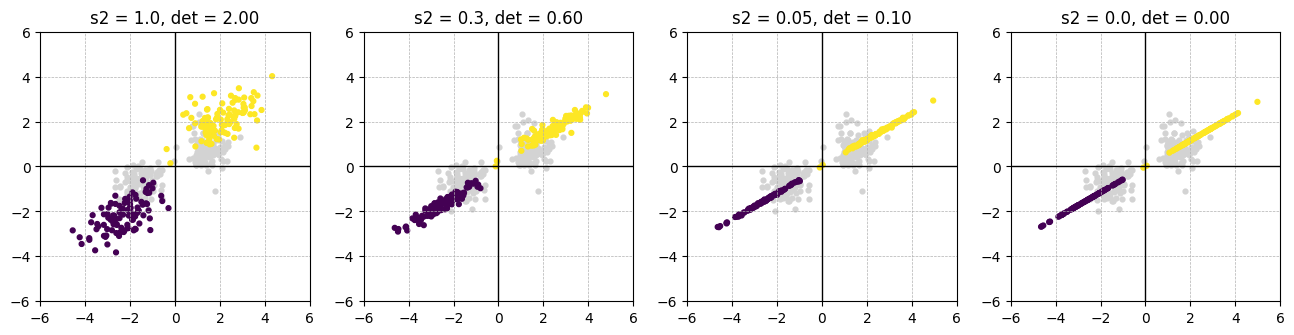

s2 = 1.0: largest error after going back = 4.4e-16
s2 = 0.3: largest error after going back = 1.3e-15
s2 = 0.05: largest error after going back = 6.7e-15
s2 = 0.0: det = 0, there is no inverse.


In [7]:
R = rotation(np.pi / 6)
values = [1.0, 0.3, 0.05, 0.0]
show([R @ scaling(2, s2) for s2 in values], [f"s2 = {s2}, det = {2 * s2:.2f}" for s2 in values])

for s2 in values:
    A = R @ scaling(2, s2)
    if s2 == 0:
        print(f"s2 = {s2}: det = 0, there is no inverse.")
    else:
        back = (X @ A.T) @ np.linalg.inv(A).T
        print(f"s2 = {s2}: largest error after going back = {np.abs(back - X).max():.1e}")

At $s_2 = 0$ two different vectors give the same result. Seeing only the result, you cannot know which one you had.

The reason: $S(x_1, x_2) = (2x_1, 0)$ forgets $x_2$. In other words, $\mathbf{d} = \mathbf{x}_a - \mathbf{x}_b$ is not zero, but
$A\mathbf{d} = \mathbf{0}$.

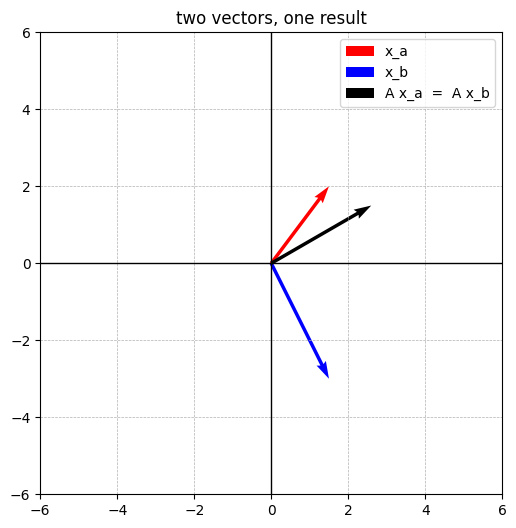

[2.59807621 1.5       ] [2.59807621 1.5       ]


In [8]:
A = rotation(np.pi / 6) @ scaling(2, 0)
x_a = np.array([1.5, 2.0])
x_b = np.array([1.5, -3.0])

fig, ax = plt.subplots(figsize=(6, 6))
arrow(ax, x_a, "red", "x_a"); arrow(ax, x_b, "blue", "x_b")
arrow(ax, A @ x_a, "black", "A x_a  =  A x_b")
axes(ax, "two vectors, one result"); ax.legend(); plt.show()
print(A @ x_a, A @ x_b)

## 7. Almost crushed: small errors become large

Before $s_2$ reaches 0 you *can* go back. But suppose $\mathbf{b}$ is measured with a tiny error $\boldsymbol\delta$:

$$\mathbf{x}_{\text{found}} = A^{-1}(\mathbf{b} + \boldsymbol\delta) = \mathbf{x}_{\text{true}} + A^{-1}\boldsymbol\delta.$$

With $A = RS$, one direction of the error is multiplied by $1/s_1$ and the other by $1/s_2$.

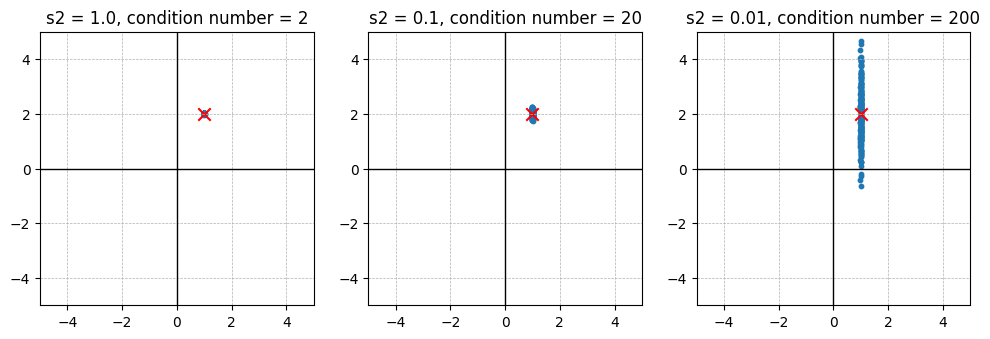

In [9]:
x_true = np.array([1.0, 2.0])
noise = rng.normal(0, 0.01, (200, 2))                  # tiny errors in b
values = [1.0, 0.1, 0.01]

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
for ax, s2 in zip(axs, values):
    A = rotation(np.pi / 6) @ scaling(2, s2)
    b_noisy = A @ x_true + noise
    x_found = np.linalg.solve(A, b_noisy.T).T          # solve for every noisy b
    ax.scatter(*x_found.T, s=10)
    ax.scatter(*x_true, c="red", marker="x", s=80)
    axes(ax, f"s2 = {s2}, condition number = {np.linalg.cond(A):.0f}", lim=5)
plt.show()

The blue points are the solutions, the red cross is the true $\mathbf{x}$. The errors in $\mathbf{b}$ are the same in all
three pictures. The **condition number** is the largest stretch
of $A$ divided by its smallest stretch. Here that is $s_1/s_2 = 2/s_2$. It limits how much a *relative* error can grow:

$$\frac{\|\delta\mathbf{x}\|}{\|\mathbf{x}\|} \le \mathrm{cond}(A)\,\frac{\|\boldsymbol\delta\|}{\|\mathbf{b}\|}.$$

**Your turn:** try `A = np.array([[1, 1], [1, 1.001]])`. What is its determinant? Its condition number?

## 8. A matrix that crushes the plane onto a line

$$B\mathbf{x} = \begin{pmatrix} 1 & 2\\ 2 & 4\end{pmatrix}\begin{pmatrix} x_1\\ x_2\end{pmatrix}
= (x_1 + 2x_2)\begin{pmatrix} 1\\ 2\end{pmatrix}.$$

Every result is a multiple of $(1, 2)$, and $\det B = 1\cdot 4 - 2\cdot 2 = 0$.
For $\mathbf{b} = (3, 6)$ we only need $x_1 + 2x_2 = 3$, so every $\mathbf{x} = (3, 0) + t\,(-2, 1)$ is a solution.

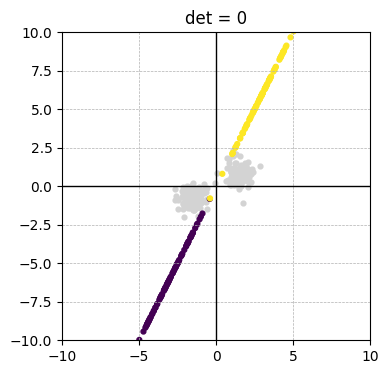

[3 6] [3 6]


In [10]:
B = np.array([[1, 2],
              [2, 4]])
show([B], [f"det = {np.linalg.det(B):.0f}"], lim=10)
print(B @ [3, 0], B @ [1, 1])      # two different x, the same b

**Your turn:** is there an $\mathbf{x}$ with $B\mathbf{x} = (3, 5)$? Answer using the picture.